# PREDICTION OF GAMBLING ADDICTION
**DOI**: [https://doi.org/10.1093/eurpub/ckp232](https://doi.org/10.1093/eurpub/ckp232)

**From the authors**: "The datasets contain raw and analytic data representing twenty four months of aggregated betting behaviour data for 530 sequential bwin Internet casino subscribers who opened an account with bwin during the period from February 1, 2005 through February 28,
2005 and closed it 30 or more days later. These subscribers had at least one non-zero betting activity during the study period (February
1, 2005 till January 31, 2007) and played live action more than 3 time during the 24 month period and more than 1 time during their
first month of betting. The DOA excluded records that took place before the first pay-in date (i.e., variable Fstpdate in raw dataset Demographics) in the preparation of this dataset. The exclusion controlled for activities financed by promotional money that might not reflect the participants behaviour when personal funds are at stake".

**Additional information** about the dataset: [http://www.thetransparencyproject.org/codebooks/Codebook_forHighRisk1.pdf](http://www.thetransparencyproject.org/codebooks/Codebook_forHighRisk1.pdf)

In [ ]:
import sklearn
import pandas as pd
import numpy as np
import itertools
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy as sp

import random
random.seed(42)
import imblearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.model_selection import learning_curve, validation_curve, train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV, cross_validate, RepeatedStratifiedKFold
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KDTree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder, OrdinalEncoder, MinMaxScaler, KBinsDiscretizer
from sklearn.datasets import fetch_openml
from xgboost import XGBClassifier

from scipy.stats import loguniform, beta, uniform

from mlxtend.feature_selection import SequentialFeatureSelector as SFS

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as IMBPipeline

import missingno as msno

import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Preliminary inspection

In [ ]:
import glob
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

file_path = glob.glob('/content/drive/My Drive/**/AnalyticDataSet_HighRisk_new.csv', recursive=True)[0]
df = pd.read_csv(file_path).copy()

Mounted at /content/drive


In [ ]:
'''
# df = pd.read_csv('AnalyticDataSet_HighRisk_new.csv')
existing_columns = df.columns

# Create a list of columns to drop, filtering out those that don't exist
# columns_to_drop = [col for col in ['Zp2stakeslope1m', 'Zp2totalactivedays1m', 'Zp2stakeSD1m', 'Zp2bpd1m','random', 'p2clusteringactivity', 'p2clusterhalf1', 'p2clusterhalf2'] if col in existing_columns]
columns_to_drop = [col for col in ['random', 'CountryID'] if col in existing_columns]


# Drop only the existing columns
df = df.drop(columns_to_drop, axis=1)

# Modify the Sereason column
df['Sereason'] = df['Sereason'].replace({1: 0, 2: 0, 3: 1})
df
'''

"\n# df = pd.read_csv('AnalyticDataSet_HighRisk_new.csv')\nexisting_columns = df.columns\n\n# Create a list of columns to drop, filtering out those that don't exist\n# columns_to_drop = [col for col in ['Zp2stakeslope1m', 'Zp2totalactivedays1m', 'Zp2stakeSD1m', 'Zp2bpd1m','random', 'p2clusteringactivity', 'p2clusterhalf1', 'p2clusterhalf2'] if col in existing_columns]\ncolumns_to_drop = [col for col in ['random', 'CountryID'] if col in existing_columns]\n\n\n# Drop only the existing columns\ndf = df.drop(columns_to_drop, axis=1)\n\n# Modify the Sereason column\ndf['Sereason'] = df['Sereason'].replace({1: 0, 2: 0, 3: 1})\ndf\n"

In [ ]:
# df = pd.read_csv('AnalyticDataSet_HighRisk_new.csv')
#existing_columns = df.columns
# Create a list of columns to drop, filtering out those that don't exist
# columns_to_drop = [col for col in ['Zp2stakeslope1m', 'Zp2totalactivedays1m', 'Zp2stakeSD1m', 'Zp2bpd1m','random', 'p2clusteringactivity', 'p2clusterhalf1', 'p2clusterhalf2'] if col in existing_columns]



# Modify the Clusterig column
df['p2cluster'] = df[['p2clusterhalf1', 'p2clusterhalf2']].max(axis=1)

existing_columns = df.columns
columns_to_drop = [col for col in ['random', 'p2clusterhalf1', 'p2clusterhalf2', 'CountryID', 'p2clusteringactivity'] if col in existing_columns]

# Drop only the existing columns
df = df.drop(columns_to_drop, axis=1)

df['p2cluster'] = df['p2cluster'].replace({1: 0, 2: 1, 3: 2, 4:3})


In [ ]:
# Dataset overview: type of features and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   UserID                530 non-null    int64  
 1   Gender                530 non-null    int64  
 2   ageRDATE              530 non-null    int64  
 3   Sereason              530 non-null    int64  
 4   p2sumstake            530 non-null    float64
 5   p2sumbet              530 non-null    int64  
 6   p2sumday              530 non-null    int64  
 7   p2intvday             530 non-null    int64  
 8   p2bpd                 530 non-null    float64
 9   p2net                 530 non-null    float64
 10  p2bpd1m               530 non-null    float64
 11  p2stakeSD1m           530 non-null    float64
 12  p2totalactivedays1m   530 non-null    int64  
 13  p2stakeSlope1m        530 non-null    float64
 14  Zp2bpd1m              530 non-null    float64
 15  Zp2stakeSD1m          5

In [ ]:
df['Gender'].value_counts()

,count
Gender,
1,486
0,44


In [ ]:
# Checking for missing values
df.isnull().sum(axis=0)

,0
UserID,0
Gender,0
ageRDATE,0
Sereason,0
p2sumstake,0
p2sumbet,0
p2sumday,0
p2intvday,0
p2bpd,0
p2net,0


In [ ]:
# Count the occurrences of each class
p2cluster_counts = df['p2cluster'].value_counts()
print(p2cluster_counts)


p2cluster
3    371
2    107
1     33
0     19
Name: count, dtype: int64


Therefore, the classes are unbalanced

## Features distribution
In order to provide a deeper understanding of the features, their distributions are shown in appropriate plots. Numerical features can be represented through histograms, while categorical features are displayed using countplots (which count the number of occurrences of each category).

In [ ]:
# Drop rows with any NaN values before feature type distinction
df_no_nan = df.dropna()

# Distinguish between numerical and categorical features (using df_no_nan)
numerical_columns = df_no_nan.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns = df_no_nan.select_dtypes(exclude=[np.number]).columns.tolist()

# Remove individual elements instead of a list
for col in ['UserID', 'Sereason', 'Gender', 'p2cluster']:
    if col in numerical_columns:
        numerical_columns.remove(col)
        categorical_columns.append(col)
categorical_columns.remove('UserID')

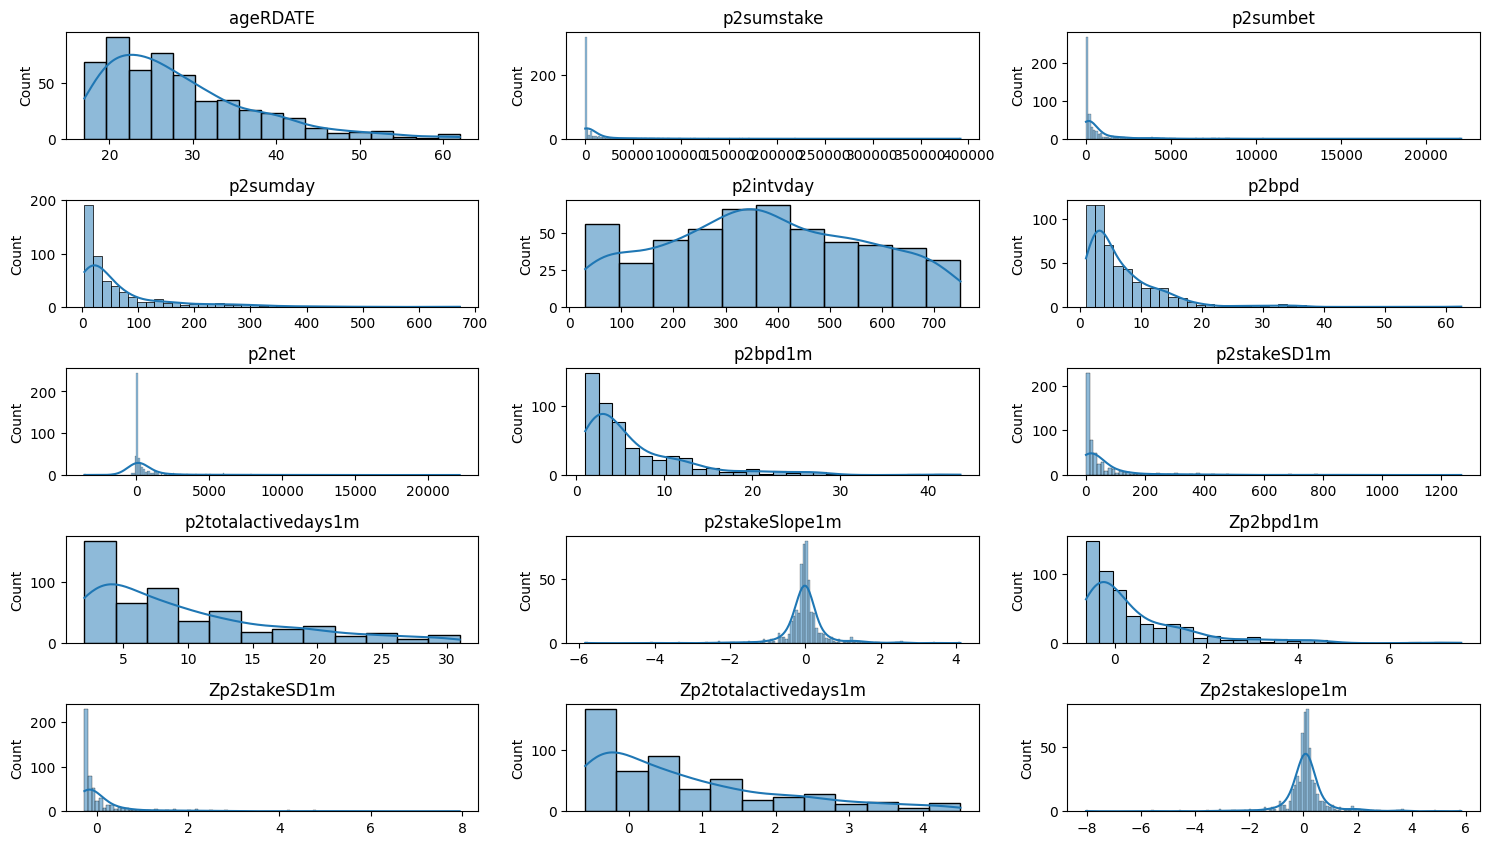

In [ ]:
# Show the distribution of numerical features (without NaN values)
plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_columns):
    plt.subplot((len(numerical_columns) // 3) + 1, 3, i+1)
    sns.histplot(df_no_nan[feature], kde=True)
    plt.title(feature)
    plt.xlabel('')
plt.tight_layout()
plt.show()

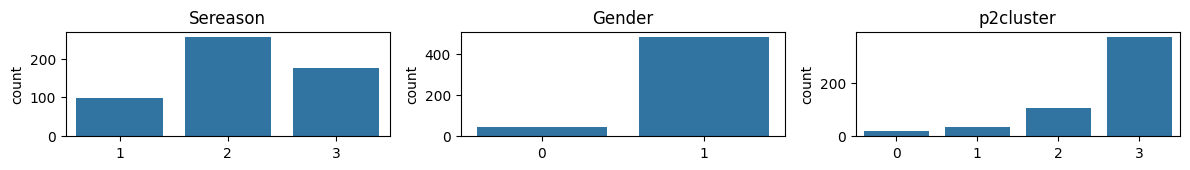

In [ ]:
# distribution of categorical features
plt.figure(figsize=(12, 3))
for i, feature in enumerate(categorical_columns):
    plt.subplot((len(categorical_columns) // 3) + 1, 3, i+1)
    sns.countplot(data=df, x=feature)
    plt.title(feature)
    plt.xlabel('')
plt.tight_layout()
plt.show()

In [ ]:
# prompt: get a list with the colum names

print(list(df.columns))


['UserID', 'Gender', 'ageRDATE', 'Sereason', 'p2sumstake', 'p2sumbet', 'p2sumday', 'p2intvday', 'p2bpd', 'p2net', 'p2bpd1m', 'p2stakeSD1m', 'p2totalactivedays1m', 'p2stakeSlope1m', 'Zp2bpd1m', 'Zp2stakeSD1m', 'Zp2totalactivedays1m', 'Zp2stakeslope1m', 'p2cluster']


In [ ]:
# prompt: generate a correlation matrix with p2cluster and the 5 most correlated features
'''
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Get the absolute values of the correlations
abs_correlation_matrix = correlation_matrix.abs()

# Find the correlations with 'p2cluster'
p2cluster_correlations = abs_correlation_matrix['p2cluster'].drop('p2cluster')

# Sort the correlations in descending order and get the top 5
top_5_features = p2cluster_correlations.nlargest(5).index.tolist()

# Print the top 5 most correlated features
print("Top 5 features most correlated with 'p2cluster':", top_5_features)

# Create a correlation matrix with only the top 5 features and 'p2cluster'
top_features_df = df[['p2cluster'] + top_5_features]
top_correlation_matrix = top_features_df.corr()

# Display the correlation matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(top_correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of p2cluster and Top 5 Features')
plt.show()
'''

'\n# Calculate the correlation matrix\ncorrelation_matrix = df.corr()\n\n# Get the absolute values of the correlations\nabs_correlation_matrix = correlation_matrix.abs()\n\n# Find the correlations with \'p2cluster\'\np2cluster_correlations = abs_correlation_matrix[\'p2cluster\'].drop(\'p2cluster\')\n\n# Sort the correlations in descending order and get the top 5\ntop_5_features = p2cluster_correlations.nlargest(5).index.tolist()\n\n# Print the top 5 most correlated features\nprint("Top 5 features most correlated with \'p2cluster\':", top_5_features)\n\n# Create a correlation matrix with only the top 5 features and \'p2cluster\'\ntop_features_df = df[[\'p2cluster\'] + top_5_features]\ntop_correlation_matrix = top_features_df.corr()\n\n# Display the correlation matrix as a heatmap\nplt.figure(figsize=(8, 6))\nsns.heatmap(top_correlation_matrix, annot=True, cmap=\'coolwarm\', fmt=".2f")\nplt.title(\'Correlation Matrix of p2cluster and Top 5 Features\')\nplt.show()\n'

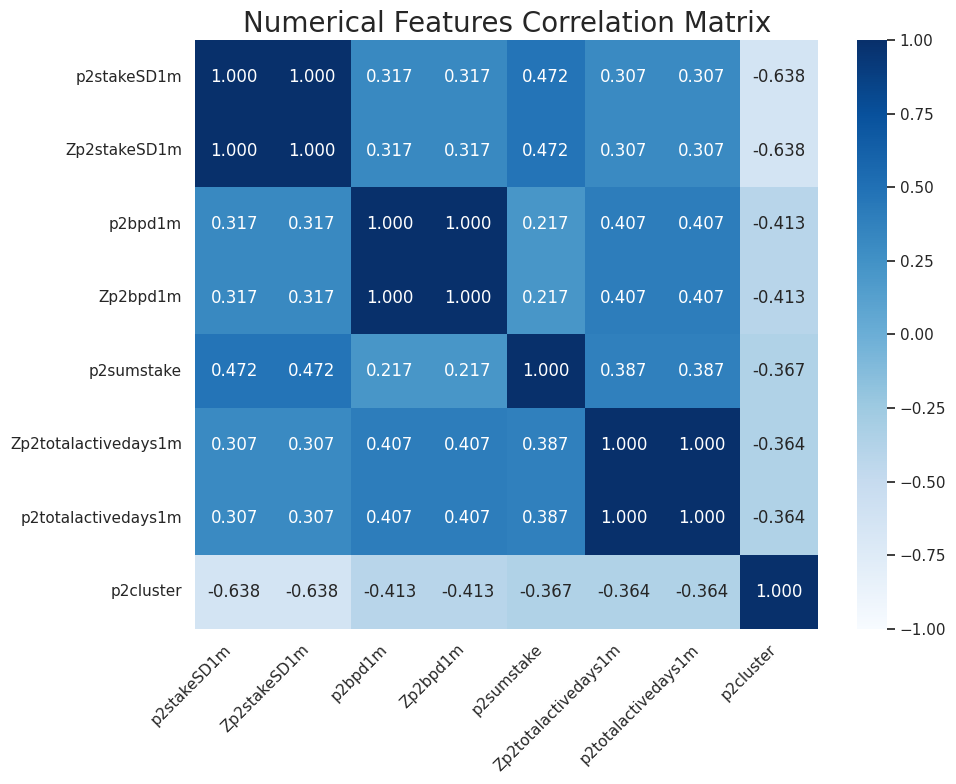

In [ ]:
# Correlation matrix


correlation_matrix = df.corr()
abs_correlation_matrix = correlation_matrix.abs()

p2cluster_correlations = abs_correlation_matrix['p2cluster'].drop('p2cluster')
top_features = p2cluster_correlations.nlargest(7).index.tolist()
# Print the top 5 most correlated features
#print("Top 5 features most correlated with 'p2cluster':", top_5_features)

# Create a correlation matrix with only the top 5 features and 'p2cluster'
top_features_df = df[top_features + ['p2cluster']]
top_correlation_matrix = top_features_df.corr()




#numerical_columns = df.select_dtypes(include=[np.number])

#correlation_columns = df[['ageRDATE', 'Sereason', 'p2sumstake', 'p2sumbet', 'p2sumday', 'p2intvday', 'p2bpd', 'p2net', 'p2bpd1m', 'p2stakeSD1m', 'p2totalactivedays1m', 'p2stakeSlope1m', 'Zp2bpd1m', 'Zp2stakeSD1m', 'Zp2totalactivedays1m', 'Zp2stakeslope1m', 'p2clusteringactivity', 'p2cluster']]


#correlation_matrix = numerical_columns.corr()
#correlation_matrix = correlation_columns.corr()

plt.figure(figsize=(10, 8))
sns.set(style="whitegrid")

heatmap = sns.heatmap(
    top_correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap='Blues',
    vmin= -1
)

plt.title('Numerical Features Correlation Matrix', fontsize=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

# Data transformation


*   Numerical, normally distributed --> **SScaler**

    
*   Numerical, non-normally distributed --> **MinMaxScaler**

In [ ]:
'''
# Distinguish between numerical and categorical features (using df_no_nan)
numerical_features = df_no_nan.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df_no_nan.select_dtypes(exclude=[np.number]).columns.tolist()


# Move individual elements
for col in ['UserID', 'Sereason', 'Gender']:
    if col in numerical_columns:
        numerical_features.remove(col)
        categorical_features.append(col)
if ['UserID'] in categorical_features:
  categorical_features.remove('UserID')
'''


# Create a custom transformer for handling skewed features
class SkewHandler(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.75):
        self.threshold = threshold
        self.skewed_features_idx = []  # Store skewed feature indices

    def fit(self, X, y=None):
        # Get skewed feature indices instead of column names
        self.skewed_features_idx = [i for i, col in enumerate(range(X.shape[1])) if abs(pd.Series(X[:, i]).skew()) > self.threshold]
        return self

    def transform(self, X):
        X_transformed = X.copy()
        # Apply transformation to skewed features using indices
        for feature_idx in self.skewed_features_idx:
          # Apply a logarithmic transformation to handle positive skew
          X_transformed[:, feature_idx] = np.log1p(X_transformed[:, feature_idx])
        return X_transformed

# Define numerical and categorical features
#numerical_features = df.select_dtypes(include=[np.number]).columns.tolist()
#categorical_features = df.select_dtypes(exclude=[np.number]).columns.tolist()
#numerical_features.remove('Sereason')

# Create pipelines for numerical and categorical features
numerical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), # Use median for numerical features
    ('skew_handler', SkewHandler()),
    ('scaler', MinMaxScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')), # Use most frequent for categorical
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])


## Train/test split

In [ ]:

# Split data into features (X) and target (y)
X = df.drop('p2cluster', axis=1)
y = df['p2cluster']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Apply the transformation pipeline
# X_transformed = df_tf.fit_transform(X)

In [ ]:
x_feature_names = list(X.columns) # Get the feature names
print(x_feature_names)

['UserID', 'Gender', 'ageRDATE', 'Sereason', 'p2sumstake', 'p2sumbet', 'p2sumday', 'p2intvday', 'p2bpd', 'p2net', 'p2bpd1m', 'p2stakeSD1m', 'p2totalactivedays1m', 'p2stakeSlope1m', 'Zp2bpd1m', 'Zp2stakeSD1m', 'Zp2totalactivedays1m', 'Zp2stakeslope1m']


In [ ]:
numerical_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Move individual elements if necessary
for col in ['UserID', 'Sereason', 'Gender']:
    if col in numerical_features:
        numerical_features.remove(col)
        categorical_features.append(col)
if 'UserID' in categorical_features:
    categorical_features.remove('UserID')

In [ ]:
# Combine transformers using ColumnTransformer
df_tf = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Model selection pipeline

Next steps: define a candidate model, select the best candidates through nested CV combining hyperparameter optimization and model selection.

First, a model is selected to check if any error occur during the implementation pipeline. The chosen model is Perceptron with PCA.

Principal component analysis (PCA) reduces the number of dimensions to principal components that retain most of the original information. It does this by transforming potentially correlated variables into a smaller set of variables, called principal components. By projecting a high-dimensional dataset into a smaller feature space, PCA also minimises common issues such as multicollinearity and overfitting. Multicollinearity occurs when two or more independent variables are highly correlated with one another, which can be problematic for causal modeling. Overfit models will generalize poorly to new data, diminishing their value altogether.

If 0 < n_components < 1 and svd_solver == 'full', select the number of components such that the amount of variance that needs to be explained is greater than the percentage specified by n_components.

Traditional techniques used in over-sampling typically rely on simple sampling with replacement. SMOTE is a different strategy where the minority class is over-sampled by generating synthetic examples. SMOTE works by creating synthetic samples along the lines joining the nearest neighbors in the feature space. The basic idea behind SMOTE is to create new minority class samples by taking small steps from one of the minority class samples to one of its k nearest neighbours in the feature space, where k is a parameter of the algorithm. The algorithm creates a new sample by randomly selecting one of the k nearest neighbors and then adding a small perturbation to the feature vector between the original sample and the selected neighbor. This creates new synthetic data that is similar to the minority class samples in the feature space but is not an exact copy of any of the existing samples.

Perceptron is considered as a single-layer neural network that consists of four main parameters named input values (Input nodes), weights and Bias, net sum, and an activation function. The perceptron model begins with the multiplication of all input values and their weights, then adds these values together to create the weighted sum. Then this weighted sum is applied to the activation function 'f' to obtain the desired output. This activation function is also known as the step function and it plays a vital role in ensuring that output is mapped between required values.

In scikit-learn, the Perceptron class supports multi-class classification using the One-vs-Rest (OvR) strategy: Scikit-learn trains one binary perceptron classifier for each class; each classifier treats one class as the positive class and all other classes as the negative class; during prediction, the class with the highest decision function score is selected.



In [ ]:
# starting pipeline
model_pipeline = IMBPipeline([
    ('trans', df_tf),
    ('imputer', SimpleImputer(strategy='median')),
    ('sampler', SMOTE()),
    ('dim_reduction', PCA(n_components=0.8)),
    ('classifier', Perceptron())
])

In [ ]:
# run  fit and predict to verify if errors occur
model_pipeline.fit(X_train,y_train)

Pipeline(steps=[('trans',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('skew_handler',
                                                                   SkewHandler()),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['ageRDATE', 'p2sumstake',
                                                   'p2sumbet', 'p2sumday',
                                                   'p2intvday', 'p2bpd',
                                                   'p2net', 'p2bpd1m',
                                                   'p2stakeSD1m',
                                                   'p2totalactivedays1m',
                                                   'p2stakeSlope1m', 'Zp2bpd1m',
                                                   'Zp2stakeSD1m',
                                                   'Zp2totalactivedays1m',
                                                   'Zp2stakeslope1m']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sereason', 'Gender'])])),
                ('imputer', SimpleImputer(strategy='median')),
                ('sampler', SMOTE()), ('dim_reduction', PCA(n_components=0.8)),
                ('classifier', Perceptron())])

In [ ]:
model_pipeline.predict(X_test) # run predict on test

array([2, 3, 3, 2, 2, 1, 3, 0, 1, 1, 3, 3, 2, 1, 2, 2, 3, 1, 3, 3, 3, 2,
       3, 1, 2, 3, 1, 3, 1, 3, 3, 2, 3, 1, 2, 2, 2, 0, 2, 1, 1, 3, 3, 2,
       2, 2, 1, 3, 1, 3, 0, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 3, 1, 1, 1, 1,
       2, 0, 3, 1, 2, 2, 2, 2, 3, 3, 2, 3, 1, 2, 0, 2, 2, 2, 1, 1, 2, 1,
       2, 0, 2, 3, 2, 3, 2, 2, 2, 0, 3, 2, 2, 2, 2, 2, 3, 2])

## Hyperparameters configurations

Define the possible combinations of hyperparameters which will undergo hyperparameter optimization.

Due to the high imbalance and the extremely low occurences of some classes, downsampling would lead to an excessive loss of data; upsampling techniques would be preferred, instead.

LDA is a dimensionality reduction technique which works by identifying a linear combination of features that separates or characterizes two or more classes of objects or events. LDA does this by projecting data with two or more dimensions into one dimension so that it can be more easily classified. This versatility ensures that LDA can be used for multi-class data classification problems.

Random oversampling handles dataset imbalance by increasing the number of samples of the minority class. It works by randomly duplicating existing samples (from the minority class) until its size matches the majority class or achieves a desired ratio. While effective in balancing classes, it can lead to overfitting since the same data points are repeated.

Forward Feature Selection is a feature selection technique that iteratively builds a model by adding one feature at a time, selecting the feature that maximises model performance. It starts with an empty set of features and adds the most predictive feature in each iteration until a stopping criterion is met.

Logistic regression is a supervised machine learning algorithm which utilises the logistic (or sigmoid) function to transform a linear combination of input features into a probability value ranging between 0 and 1. Typically adopted for binary classification tasks, Logistic Regression can be implemented for MCC.

The k-nearest neighbours (KNN) algorithm is a non-parametric, supervised learning classifier, which uses proximity to make classifications or predictions about the grouping of an individual data point, working off the assumption that similar points can be found near one another. For classification problems, a class label is assigned on the basis of a majority vote.

Ensemble learning methods are made up of a set of classifiers (such as decision trees) and their predictions are aggregated to identify the most popular result. The random forest algorithm is made up of a collection of decision trees, and each tree in the ensemble is comprised of a data sample drawn from a training set with replacement, called the bootstrap sample. The main benefits of Random forest are interpretability and the reduced risk of overfitting (when there’s a robust number of decision trees in a random forest, the classifier won’t overfit the model since the averaging of uncorrelated trees lowers the overall variance and prediction error).

Gradient boosting is a machine learning ensemble technique that sequentially combines the predictions of multiple weak learners, typically decision trees. It aims to improve overall predictive performance by optimising the model’s weights based on the errors of previous iterations, gradually reducing prediction errors and enhancing the model’s accuracy. The gradient boost algorithm helps to minimise the model’s bias error.



In [ ]:
sampler_configs = [
    {
        'sampler':[None],# The element is bypassed
    },
    {
        'sampler':[SMOTE()],                 # n_jobs=-1, k=5 by default
        'sampler__sampling_strategy': [
            'minority',                      # resample only the minority class
            'auto'                           # equivalent to 'not majority', resample all classes but the majority classc
        ]
    },
    {
        'sampler':[RandomOverSampler()],  # Oversampling
        'sampler__sampling_strategy': [
            'minority',                   # resample only the minority class
            'auto'                        # This will oversample all minority classes to match the majority class
        ]
    }
]

dim_reduction_configs = [
    {
        'dim_reduction': [None]
    },
    {
        'dim_reduction': [PCA()],                      # PCA
        'dim_reduction__n_components': [0.5, 0.7, 0.9] # var to keep since in [0,1]; #dim otherwise
    },
    {
        'dim_reduction': [LDA()] # LDA
    },
    {
        'dim_reduction': [SFS(estimator=Perceptron(), cv = None, forward=True, scoring = 'f1_weighted')], # Sequential (Forward) Feature Selection
        'dim_reduction__estimator': [Perceptron(), LogisticRegression()], # Perceptron or LogisticRegression
        'dim_reduction__k_features' : [5,7,10]                            # Number of features to select
    }
]

classifier_configs = [
    {
        'classifier__eta0' : loguniform(0.001,100),     # learning rates taken from loguniform distribution
        'classifier': [Perceptron()] ,                  # Perceptron
        'classifier__max_iter': [1,5,10,15,50,100] ,    # number of epochs
        'classifier__class_weight' : [None, 'balanced'] # class weights, balanced means that the weights are inversely proportional to the number of samples in the corresponding class

    },
    {
        'classifier': [LogisticRegression(solver='saga')], # LogisticRegression
        'classifier__C' : loguniform(0.001,100),           # C taken from loguniform distribution
        'classifier__penalty': ['l1','l2'],                # L1 and L2 regularization
        'classifier__class_weight' : [None, 'balanced']    # class weights

    },
    {
        'classifier': [KNeighborsClassifier()], # KNeighborsClassifier
        'classifier__n_neighbors': [3,5,7,9]    # number of neighbors
    },
    {
        'classifier' : [RandomForestClassifier()],    # RandomForestClassifier
        'classifier__n_estimators' : [10,50,100, 500] # number of estimators, the number of trees in the forest
    },
    {
        'classifier' : [XGBClassifier()],                           # XGBClassifier
        'classifier__n_estimators' : [10,50,100, 500],              # number of estimators
        'classifier__learning_rate' : [0.001, 0.01, 0.1, 0.3, 0.5], # learning rate
        'classifier__max_depth' : [4, 6, 8, 10]                     # max depth of the trees
    }
]


## Nested CV

The use of nested-cross validation allow to identify 5 different best candidates to be the reference model.

Nested CV is composed by an outer loop (CV using as hyperparameter the best candidate identified in the inner loop) to and an inner loop (hyperparameter optimisation using Randomized Grid Search). Nested CV estimates the generalisation error of the underlying model and its (hyper)parameter search. Choosing the parameters that maximize non-nested CV biases the model to the dataset, yielding an overly-optimistic score.



In [ ]:
# create a list of all possible configurations to be passed to RandomSearchCV object
all_configs = []
for configuration in itertools.product(sampler_configs,dim_reduction_configs,classifier_configs): # itertools.product returns the cartesian product of the lists passed as arguments
    # Merging of three dictionary into one
    all_parameters = []
    for element in configuration:
        for item in element.items():
            all_parameters.append(item)
    all_configs.append(dict(all_parameters)) # by dict(all_parameters), create a dict from a list of pairs (key:value)

print(f'Number of all possible configurations: {len(all_configs)}')

Number of all possible configurations: 60


The following snippet defines a RandomizedSearchCV object which takes the list of all configurations and uses a 2-fold cross validation using F1 as scoring metric. The number of sampled configurations should be al least ten times the length of all possible configurations.

Then, implement the outer loop using the function cross_validate, using F1 as score metric, 5-fold cross-validation. To get the best estimators for each fold,  set return_estimator=True.

The output of cross_validate is a dictionary providing all the information for each cross-validation iteration:

- the best estimator returns by the randomized grid search

- the hyperparameter of the best estimator. You have to inspect the value associated to estimator

- the score on the validation fold for the best estimator.



In [ ]:
# inner loop
rs = RandomizedSearchCV(model_pipeline,
    param_distributions=all_configs,
    n_iter=len(all_configs) * 5, # number of sampled configurations should be at least 5 times the length of all possible configurations
    n_jobs=-1,                   # use all available cores
    cv = 2,                      # 2-fold cross validation
    scoring='f1'                 # F1 as scoring
)

# outer loop
scores = cross_validate(rs, X_train, y_train, scoring='f1_weighted', cv = 5, return_estimator=True, verbose=3)
 # return_estimator=True to get the best estimator for each fold
 # cv = 5 for 5-fold cross validation
 # verbose=3 to see the progress of the outer loop
 # scoring = f1_weighted for F1 as scoring

[CV] END ......................................., score=0.697 total time= 2.4min
[CV] END ......................................., score=0.542 total time= 2.6min
[CV] END ......................................., score=0.775 total time= 2.5min
[CV] END ......................................., score=0.751 total time= 2.3min
[CV] END ......................................., score=0.807 total time= 2.5min


As anticipated, the code implements nested cross-validation for hyperparameter tuning and model evaluation. The inner loop uses RandomizedSearchCV to find the best hyperparameters for a model pipeline by sampling configurations (n_iter), performing 2-fold cross-validation, and optimizing for the F1 score. It uses all CPU cores (n_jobs=-1). The outer loop applies cross_validate with 5-fold cross-validation to evaluate the model's performance on different data splits, using the weighted F1 score. This process ensures robust hyperparameter tuning while minimizing overfitting and providing an unbiased performance estimate. Trained models for each fold are also returned.

The weighted F1 score is ideal for handling imbalanced datasets. It computes the F1 score for each class and weights them based on class frequencies, ensuring the final score reflects the dataset's composition. This approach prevents dominant classes from overshadowing minority ones. By providing a balanced evaluation of performance across all classes, the weighted F1 score is more reliable than metrics like accuracy, making it a robust choice for imbalanced classification problems.



In [ ]:
for index, estimator in enumerate(scores['estimator']):
    print(estimator.best_estimator_.get_params()['sampler'])
    print(estimator.best_estimator_.get_params()['dim_reduction'])
    print(estimator.best_estimator_.get_params()['classifier'],estimator.best_estimator_.get_params()['classifier'].get_params())
    print(scores['test_score'][index])
    print('-'*10)

SMOTE(sampling_strategy='minority')
PCA(n_components=0.9)
Perceptron(class_weight='balanced', eta0=np.float64(0.0029137822737765866),
           max_iter=10) {'alpha': 0.0001, 'class_weight': 'balanced', 'early_stopping': False, 'eta0': np.float64(0.0029137822737765866), 'fit_intercept': True, 'l1_ratio': 0.15, 'max_iter': 10, 'n_iter_no_change': 5, 'n_jobs': None, 'penalty': None, 'random_state': 0, 'shuffle': True, 'tol': 0.001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
0.6972549019607843
----------
SMOTE(sampling_strategy='minority')
PCA(n_components=0.7)
Perceptron(class_weight='balanced', eta0=np.float64(0.0020235723511757317),
           max_iter=100) {'alpha': 0.0001, 'class_weight': 'balanced', 'early_stopping': False, 'eta0': np.float64(0.0020235723511757317), 'fit_intercept': True, 'l1_ratio': 0.15, 'max_iter': 100, 'n_iter_no_change': 5, 'n_jobs': None, 'penalty': None, 'random_state': 0, 'shuffle': True, 'tol': 0.001, 'validation_fraction': 0.1, 'verbos

To further reduce the number of candidates, re-train the above  model on the entire training set and evaluate their performance on the test set.

In [ ]:
from sklearn.metrics import f1_score

for estimator in scores['estimator']:
    pred_train = estimator.best_estimator_.fit(X_train, y_train)
    pred_train = estimator.best_estimator_.predict(X_train)
    pred_test = estimator.best_estimator_.predict(X_test)

    # Calculate F1-score with 'weighted' averaging for multiclass
    f1_train = f1_score(y_train, pred_train, average='weighted')
    f1_test = f1_score(y_test, pred_test, average='weighted')

    print(f'F1 on training set:{f1_train}, F1 on test set:{f1_test}')

F1 on training set:0.7018799392873591, F1 on test set:0.6764446161129057
F1 on training set:0.3053089814888894, F1 on test set:0.26202156750255545
F1 on training set:1.0, F1 on test set:0.7814585205151243
F1 on training set:1.0, F1 on test set:0.6868292085273218
F1 on training set:0.8778987992696977, F1 on test set:0.7821988695167582


In [ ]:
#  print the configuration of the best estimator, use the get_params() method of the best estimator and extract the specific configurations you want to print.
for estimator in scores['estimator']:
    # Get the configuration of the best estimator
    best_estimator_params = estimator.best_estimator_.get_params() # get the configuration of the best estimator

    # Extract the specific configurations to print
    sampler = best_estimator_params['sampler']             # sampler
    dim_reduction = best_estimator_params['dim_reduction'] # dimensionality reduction
    classifier = best_estimator_params['classifier']       # classifier

    # Print the configurations
    print("Configurations used:")
    print(f"  Sampler: {sampler}")
    print(f"  Dimensionality Reduction: {dim_reduction}")
    print(f"  Classifier: {classifier}")
    print("-" * 20)  # Separator for better readability

    pred_train = estimator.best_estimator_.fit(X_train, y_train) # train the model
    pred_train = estimator.best_estimator_.predict(X_train)      # predict on the train set
    pred_test = estimator.best_estimator_.predict(X_test)        # predict on the test set

    # Calculate F1-score with 'weighted' averaging for multiclass
    f1_train = f1_score(y_train, pred_train, average='weighted') # calculate F1-score with 'weighted' averaging for multiclass on the train set
    f1_test = f1_score(y_test, pred_test, average='weighted')    # calculate F1-score with 'weighted' averaging for multiclass on the test set

    print(f'F1 on training set:{f1_train}, F1 on test set:{f1_test}')
    print("=" * 40)  # Separator between models

Configurations used:
  Sampler: SMOTE(sampling_strategy='minority')
  Dimensionality Reduction: PCA(n_components=0.9)
  Classifier: Perceptron(class_weight='balanced', eta0=np.float64(0.0029137822737765866),
           max_iter=10)
--------------------
F1 on training set:0.8302975602747031, F1 on test set:0.7734096692111958
Configurations used:
  Sampler: SMOTE(sampling_strategy='minority')
  Dimensionality Reduction: PCA(n_components=0.7)
  Classifier: Perceptron(class_weight='balanced', eta0=np.float64(0.0020235723511757317),
           max_iter=100)
--------------------
F1 on training set:0.33438543671360893, F1 on test set:0.2816867095168982
Configurations used:
  Sampler: SMOTE()
  Dimensionality Reduction: PCA(n_components=0.7)
  Classifier: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, ev

Configurations used (optimal configuration found):
Configurations used:
  - Sampler: None
  - Dimensionality Reduction: None
  - Classifier: XGBClassifier

## Model refinement

Re-run the hyperparameter optmization fixing the modelling approach and varying the hyperparameters in a range close to selected model's one.

In [ ]:
'''
best_model_pipeline = IMBPipeline([
    ('trans', df_tf),
    ('imputer', SimpleImputer(strategy='median')),
    ('sampler', SMOTE()),
    ('dim_reduction', PCA(n_components=0.9)),
    ('classifier',Perceptron(eta0=np.float64(10.907744817507448), max_iter=50))
])
'''

"\nbest_model_pipeline = IMBPipeline([\n    ('trans', df_tf),\n    ('imputer', SimpleImputer(strategy='median')),\n    ('sampler', SMOTE()),\n    ('dim_reduction', PCA(n_components=0.9)),\n    ('classifier',Perceptron(eta0=np.float64(10.907744817507448), max_iter=50))\n])\n"

In [ ]:
best_model_pipeline = IMBPipeline([
    ('trans', df_tf),
    ('imputer', SimpleImputer(strategy='median')),
    ('sampler', None),
    ('dim_reduction', None),
    ('classifier',XGBClassifier())
])

In [ ]:
params ={
        'classifier__n_estimators' : [10,50,100, 500],              # number of estimators
        'classifier__learning_rate' : [0.001, 0.01, 0.1, 0.3, 0.5], # learning rate
        'classifier__max_depth' : [4, 6, 8, 10]                     # max depth of the trees
    }

In [ ]:
rs_best = RandomizedSearchCV(
    estimator = best_model_pipeline,
    param_distributions = params,
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=1),
    n_iter=20,
    scoring='f1'
)

In [ ]:
rs_best.fit(X_train, y_train)

RandomizedSearchCV(cv=RepeatedStratifiedKFold(n_repeats=1, n_splits=5, random_state=None),
                   estimator=Pipeline(steps=[('trans',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('skew_handler',
                                                                                                SkewHandler()),
                                                                                               ('scaler',
                                                                                                MinMaxScaler())]),
                                                                               ['ageRDATE',
                                                                                'p2sumstake',
                                                                                'p2sumbet',
                                                                                'p2sumday',
                                                                                'p2intvday',
                                                                                'p2bpd',
                                                                                '...
                                                            max_leaves=None,
                                                            min_child_weight=None,
                                                            missing=nan,
                                                            monotone_constraints=None,
                                                            multi_strategy=None,
                                                            n_estimators=None,
                                                            n_jobs=None,
                                                            num_parallel_tree=None,
                                                            random_state=None, ...))]),
                   n_iter=20,
                   param_distributions={'classifier__learning_rate': [0.001,
                                                                      0.01, 0.1,
                                                                      0.3,
                                                                      0.5],
                                        'classifier__max_depth': [4, 6, 8, 10],
                                        'classifier__n_estimators': [10, 50,
                                                                     100,
                                                                     500]},
                   scoring='f1')

In [ ]:
rs_best.best_estimator_

Pipeline(steps=[('trans',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('skew_handler',
                                                                   SkewHandler()),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['ageRDATE', 'p2sumstake',
                                                   'p2sumbet', 'p2sumday',
                                                   'p2intvday', 'p2bpd',
                                                   'p2net', 'p2bpd1m',
                                                   'p2stakeSD1m',
                                                   'p2totalactivedays1m',
                                                   'p2stakeSlope1m', 'Zp2bpd1m',
                                                   'Zp2stakeSD1m',
                                                   'Z...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=8, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=50, n_jobs=None,
                               num_parallel_tree=None,
                               objective='multi:softprob', ...))])

In [ ]:
# f1_score(y_test, rs_best.best_estimator_.predict(X_test))
f1_score(y_test, rs_best.best_estimator_.predict(X_test), average='weighted')

0.9295765833949307

# Learning and validation curves

Learning curves plot training and validation performance against the size of the training dataset. They help to determine if adding more data would improve the model or if the model is underfitting (low for both training and testing) or overfitting (high training , low testing).

Validation curves assess the impact of hyperparameters, plotting training and validation performance against a specific parameter. These curves highlight sensitivity to parameter values, guiding the selection of optimal configurations to avoid underfitting or overfitting.



In [ ]:
cls = rs_best.best_estimator_

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(cls,
                                                       X=X_train,
                                                       y=y_train,
                                                       train_sizes= [0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
                                                       cv = 5,
                                                       n_jobs = -1,
                                                       scoring = 'f1',
                                                       shuffle = False)

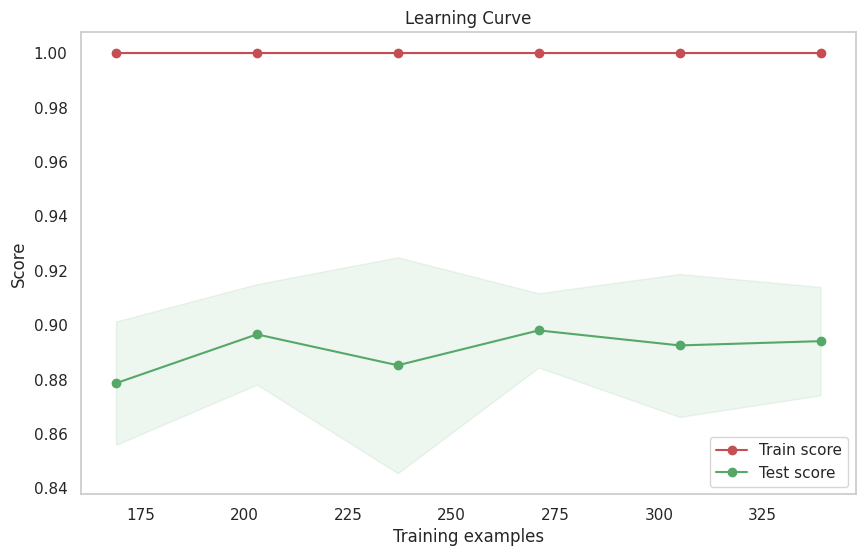

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    cls,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),  # Evenly spaced training sizes
    cv=5,                                   # Number of cross-validation folds
    scoring='f1_weighted',                  # Use weighted F1-score for multi-class
    n_jobs=-1                               # Use all available CPU cores
)

train_scores_mean = np.mean(train_scores, axis=1) # Mean score for each training size
train_scores_std = np.std(train_scores, axis=1)   # Standard deviation for each training size
test_scores_mean = np.mean(test_scores, axis=1)   # Mean score for each training size
test_scores_std = np.std(test_scores, axis=1)     # Standard deviation for each training size

# Create the learning curve plot
plt.figure(figsize=(10, 6))
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")

plt.grid()

plt.fill_between(
    train_sizes,                          # Training sizes
    train_scores_mean - train_scores_std, # Lower bound of the training score
    train_scores_mean + train_scores_std, # Upper bound of the training score
    alpha=0.1,                            # Transparency of the fill
    color="r",                            # Color of the fill
)
plt.fill_between(
    train_sizes,                        # Training sizes
    test_scores_mean - test_scores_std, # Lower bound of the test score
    test_scores_mean + test_scores_std, # Upper bound of the test score
    alpha=0.1,                          # Transparency of the fill
    color="g",                          # Color of the fill
)
plt.plot(
    train_sizes, train_scores_mean, "o-", color="r", label="Train score" # Plot the mean training score for each training size
)
plt.plot(
    train_sizes, test_scores_mean, "o-", color="g", label="Test score" # Plot the mean test score for each testing size
)

plt.legend(loc="best") # Show the legend in the best location

# Display the plot
plt.show()

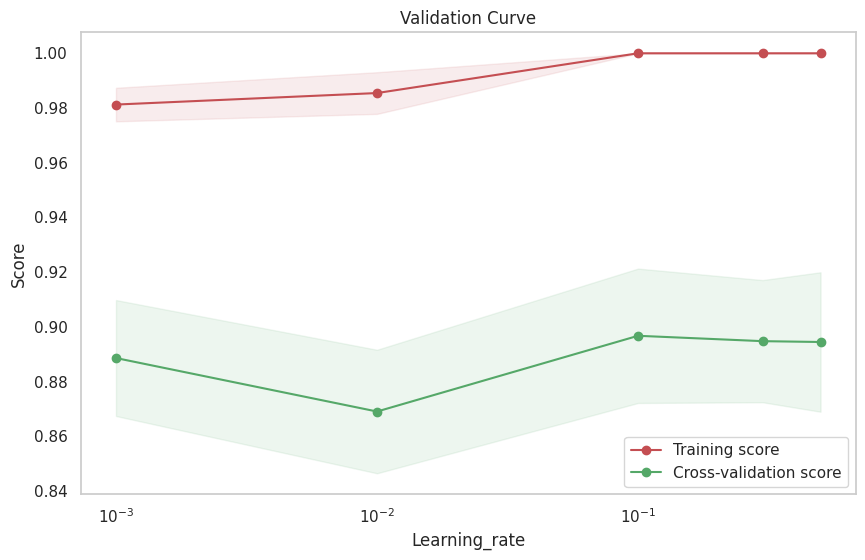

In [ ]:
# Validation curve
#param_range = np.array([0.001, 0.01, 0.1, 1, 10, 100])
param_range = [0.001, 0.01, 0.1, 0.3, 0.5]

# Use 'eta0' or 'max_iter' - valid hyperparameters for Perceptron
'''params ={
        'classifier__n_estimators' : [10,50,100, 500],              # number of estimators
        'classifier__learning_rate' : [0.001, 0.01, 0.1, 0.3, 0.5], # learning rate
        'classifier__max_depth' : [4, 6, 8, 10]                     # max depth of the trees
    }'''
param_name = "classifier__learning_rate"

train_scores, test_scores = validation_curve(
    cls,
    X=X_train,
    y=y_train,
    param_name=param_name,      # Using the correct hyperparameter name
    param_range=param_range,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

train_scores_mean = np.mean(train_scores, axis=1) # Mean score for each hyperparameter value on the training set
train_scores_std = np.std(train_scores, axis=1)   # Standard deviation for each hyperparameter value on the training set
test_scores_mean = np.mean(test_scores, axis=1)   # Mean score for each hyperparameter value on the test set
test_scores_std = np.std(test_scores, axis=1)     # Standard deviation for each hyperparameter value on the test set

# Create the validation curve plot
plt.figure(figsize=(10, 6))
plt.title("Validation Curve") # Title of the plot
plt.xlabel("Learning_rate")     # X-axis label
plt.ylabel("Score")           # Y-axis label

plt.grid()

plt.semilogx(
    param_range, train_scores_mean, "o-", color="r", label="Training score" # Plot the mean training score for each hyperparameter value
)
plt.fill_between(
    param_range,
    train_scores_mean - train_scores_std, # Lower bound of the training score
    train_scores_mean + train_scores_std, # Upper bound of the training score
    alpha=0.1,                            # Transparency of the fill
    color="r",                            # Color of the fill
)
plt.semilogx(
    param_range, test_scores_mean, "o-", color="g", label="Cross-validation score" # Plot the mean test score for each hyperparameter value
)
plt.fill_between(
    param_range,
    test_scores_mean - test_scores_std, # Lower bound of the test score
    test_scores_mean + test_scores_std, # Upper bound of the test score
    alpha=0.1,                          # Transparency of the fill
    color="g",                          # Color of the fill
)

plt.legend(loc="best")

# Display the plot
plt.show()



---



In [ ]:
import shap

# Fit the best model to the training data
best_model = rs_best.best_estimator_
best_model.fit(X_train, y_train)

# Extract the final estimator from the pipeline (the classifier)
final_estimator = best_model.named_steps['classifier']

# Use the final estimator for the SHAP explainer
explainer = shap.Explainer(final_estimator, X)
shap_values = explainer(X)

cluster  1


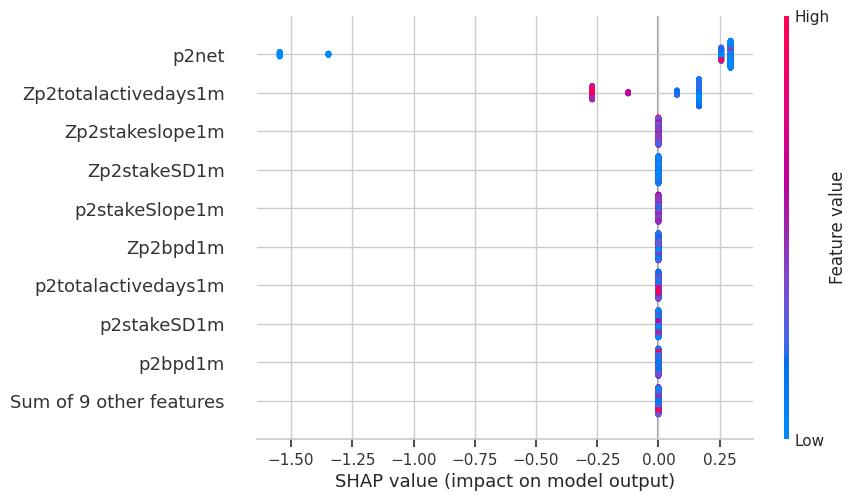

cluster  2


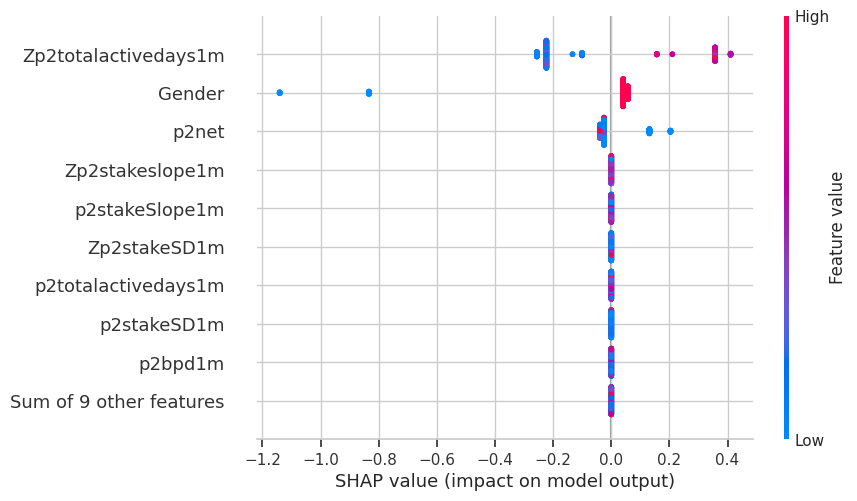

cluster  3


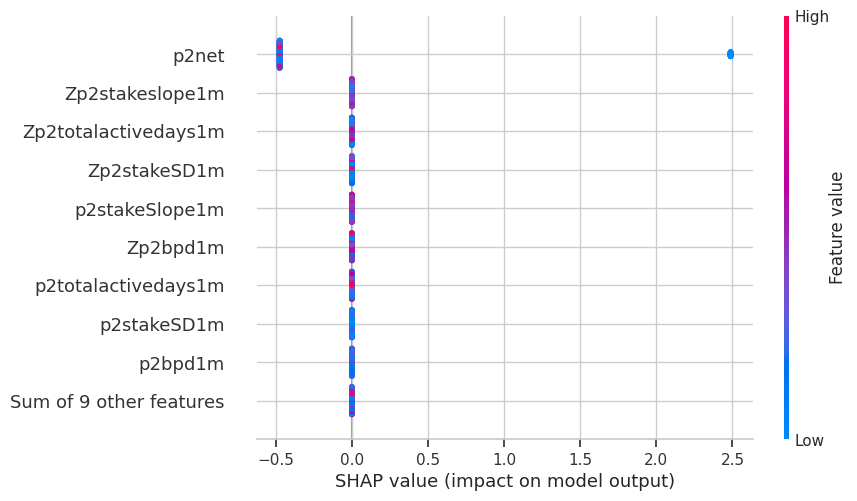

cluster  4


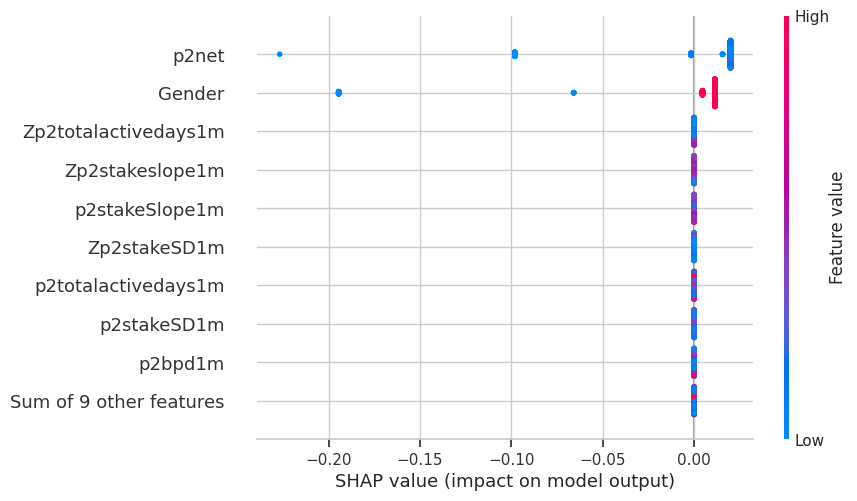

In [ ]:
# Assuming shap_values is a 3D array with shape (530, 18, 4)
# Select SHAP values for a single output (e.g., the first output)
# This will select values for one of your target classes
# shap_values_single_output = shap_values[:, :, 0]

# Now, you can use shap_values_single_output for the beeswarm plot
# shap.plots.beeswarm(shap_values_single_output, max_display=10)

# Iterate the plotting
list_shap_values = []

for i in range(4):
  #print('cluster ', (i+1))
  shap_values_single_output = shap_values[:, :, i]
  list_shap_values.append(shap_values_single_output)
  #shap.plots.beeswarm(shap_values_single_output)

for i in range(len(list_shap_values)):
  print('cluster ', (i+1))
  shap.plots.beeswarm(list_shap_values[i])


cluster  1


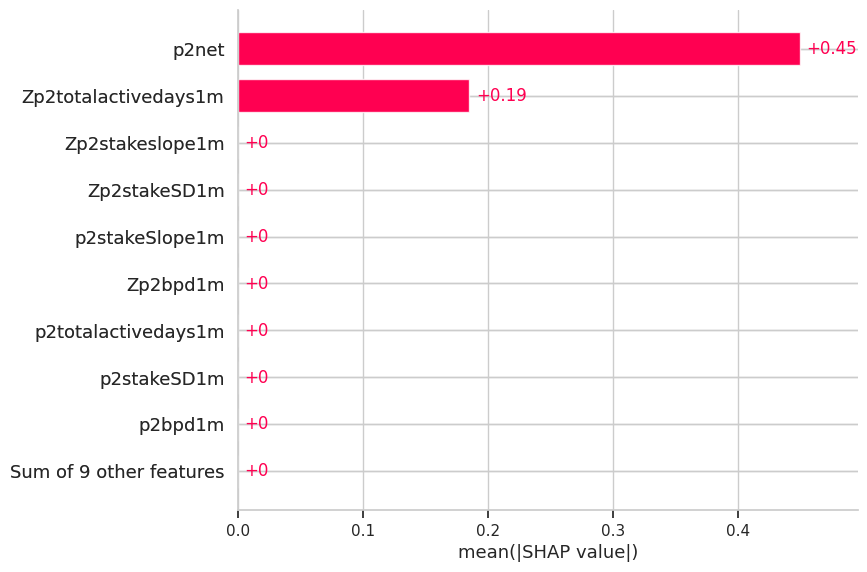

cluster  2


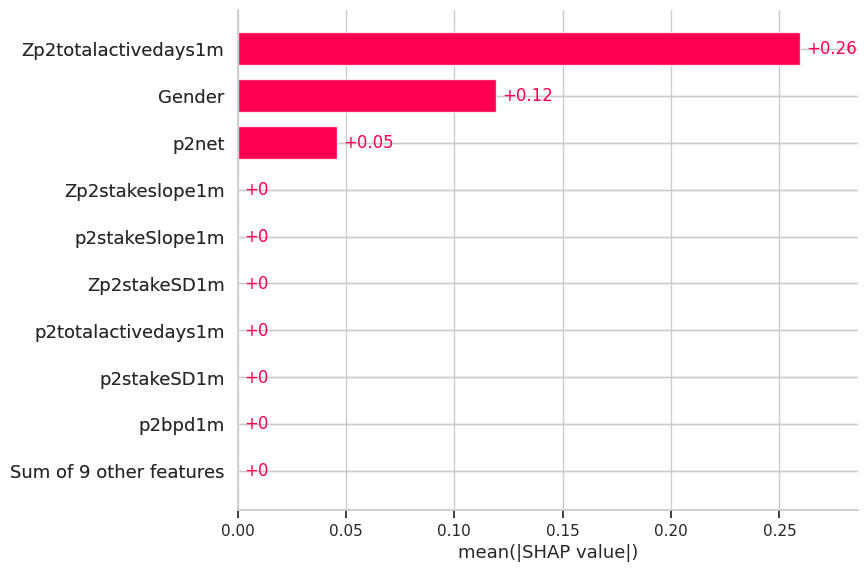

cluster  3


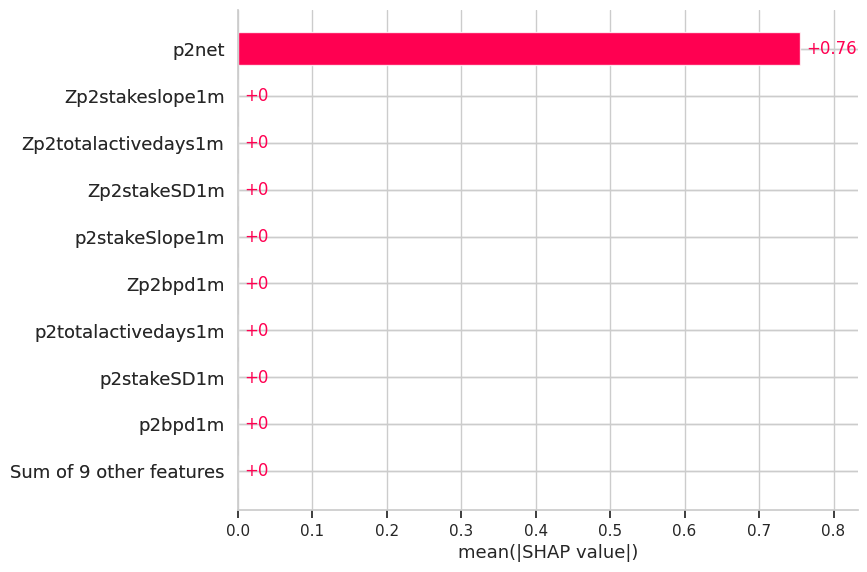

cluster  4


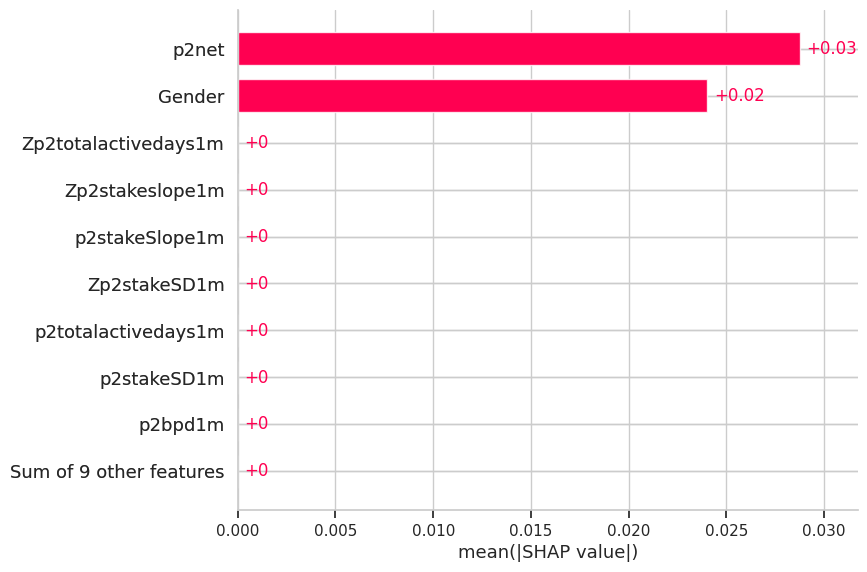

In [ ]:
for i in range(len(list_shap_values)):
  print('cluster ', (i+1))
  shap.plots.bar(list_shap_values[i])

cluster  1


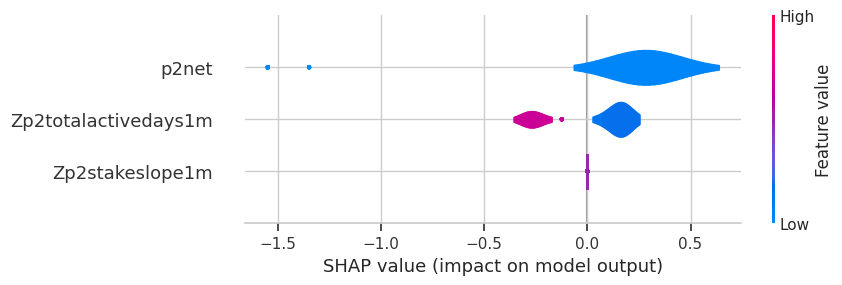

cluster  2


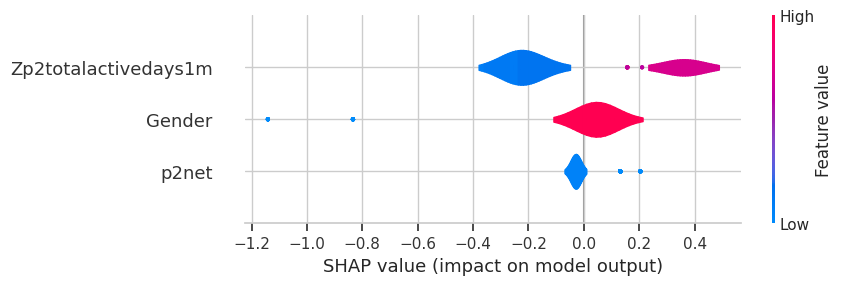

cluster  3


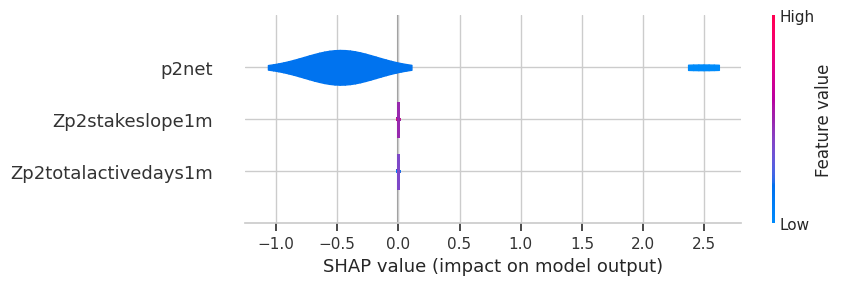

cluster  4


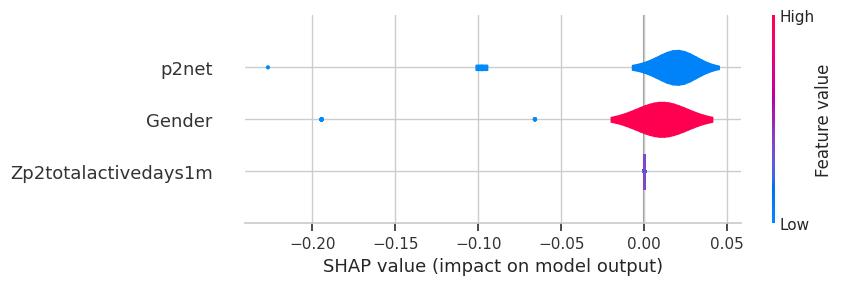

In [ ]:
for i in range(len(list_shap_values)):
  print('cluster ', (i+1))
  shap.plots.violin(list_shap_values[i], max_display=3)


SHAP library version: 0.47.1

Calculating SHAP values for the test set...
SHAP values calculated as a single array (binary or specific output).

--- Starting Fairness Analysis ---
Min age in test set: 18, Max age in test set: 62
Type of shap_values: <class 'numpy.ndarray'>
Shape of shap_values ndarray: (106, 20, 4)
Shape of calculated shap_impact_per_instance: (106,)
Successfully created shap_impact_series (1D).

Analyzing SHAP impact by Age Group...


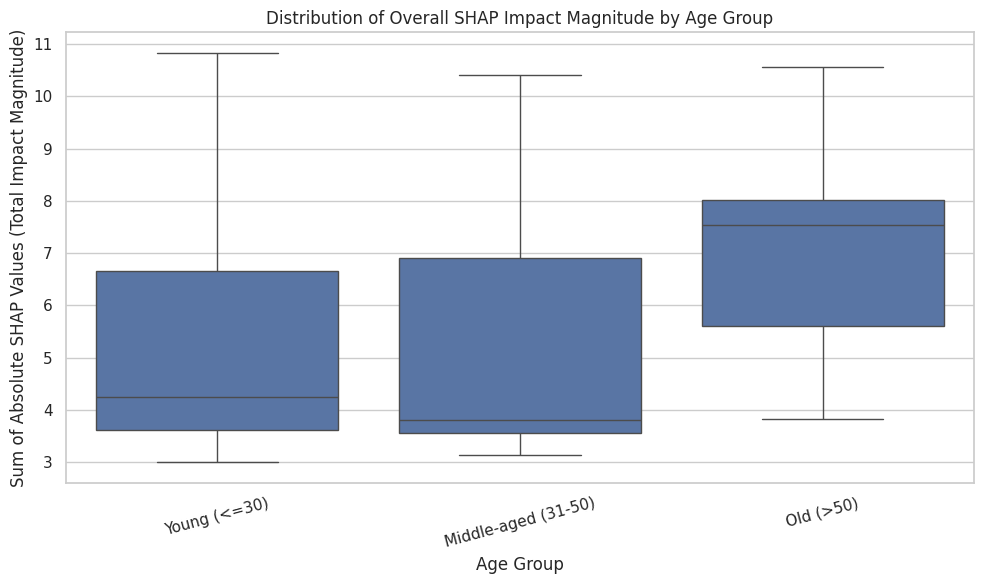


Analyzing SHAP impact by Gender...


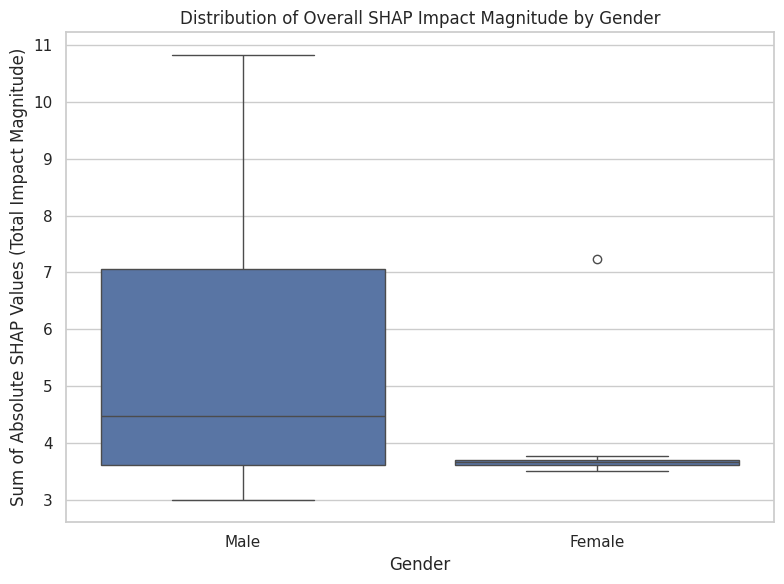


Analyzing SHAP impact by Age-Gender Group...


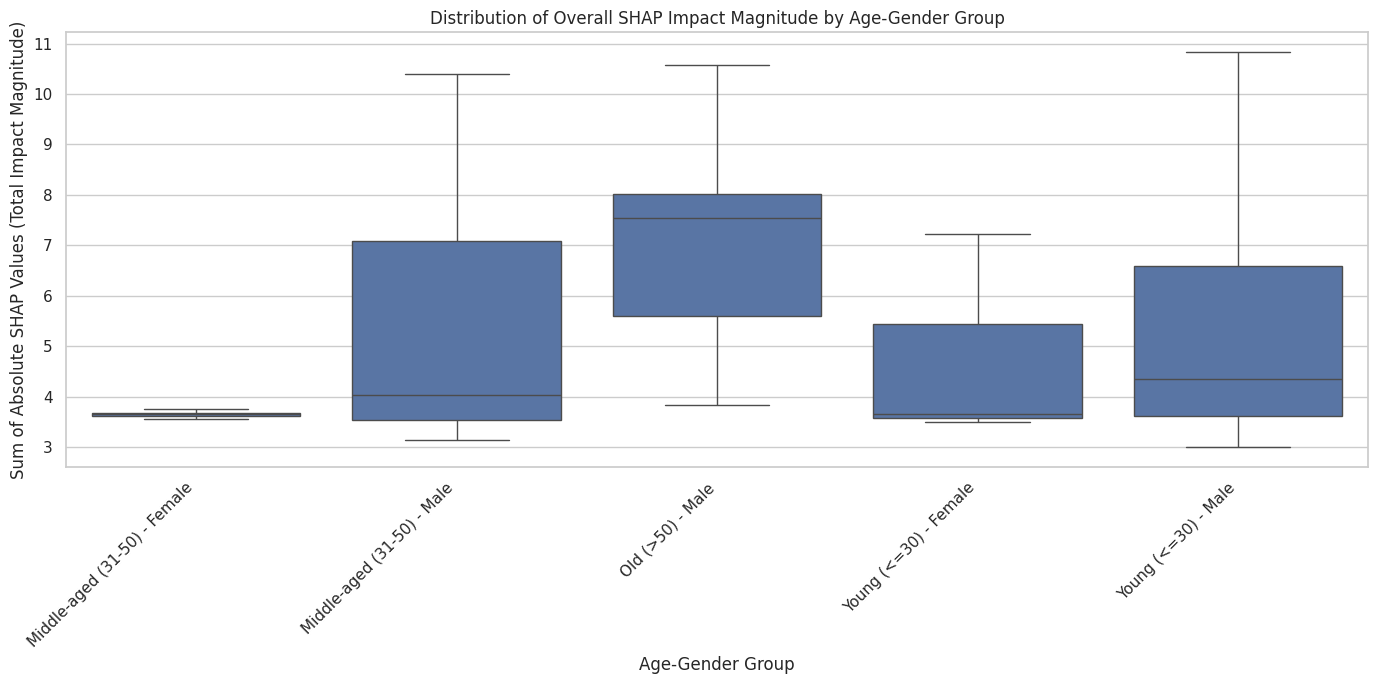

Could not find processed age column ('ageRDATE') for dependence plot.
Could not find processed gender column(s) for dependence plot.

--- SHAP Analysis Complete ---


In [ ]:
# 6. Fairness Analysis using SHAP
print(f"\nSHAP library version: {shap.__version__}")

# 2. Prepare data for SHAP
# We need the data transformed by the preprocessing steps *before* the classifier
# Get the preprocessing part of the best pipeline

#preprocessing_pipeline = best_model[:-1] # Selects all steps except the last ('classifier')
#rs_best.best_estimator_ = cls
preprocessing_pipeline = rs_best.best_estimator_[:-1]
best_model = rs_best.best_estimator_

# Apply the preprocessing pipeline to the test set (or a subset for faster computation)
# Using the full test set for better representation
X_test_processed = preprocessing_pipeline.transform(X_test)

# Get feature names after transformation (OneHotEncoder creates new names)
try:
    # Get feature names from the preprocessor step within the pipeline
    feature_names_out = best_model.named_steps['trans'].get_feature_names_out()
    #feature_names_out = get_feature_names(best_model.named_steps['trans'])
    print(f"\nNumber of features after processing: {len(feature_names_out)}")
except AttributeError:
     # Fallback if get_feature_names_out is not available or fails
     print("Warning: Could not automatically retrieve feature names after preprocessing.")
     # Manually create generic names if needed, but SHAP plots will be less informative
     feature_names_out = [f"feature_{i}" for i in range(X_test_processed.shape[1])]


# Convert processed data to DataFrame for easier handling with SHAP (optional but good practice)
X_test_processed_df = pd.DataFrame(X_test_processed, columns=feature_names_out, index=X_test.index)


# 3. Initialize SHAP Explainer
# Use TreeExplainer for XGBoost
explainer = shap.TreeExplainer(best_model.named_steps['classifier']) # Pass the trained classifier step

# 4. Calculate SHAP values
print("\nCalculating SHAP values for the test set...")
shap_values = explainer.shap_values(X_test_processed_df) # Pass the processed data

# For multi-class classification, shap_values is a list of arrays (one per class)
# For XGBoost, explainer.shap_values might return expected_value + shap_values
# Let's check the type and shape
if isinstance(shap_values, list):
    print(f"SHAP values calculated for {len(shap_values)} classes.")
    # For summary plots, we often average the absolute SHAP values across classes or focus on one class
    # Option A: Mean absolute SHAP value across all classes for global importance
    shap_values_mean_abs = np.mean([np.abs(sv) for sv in shap_values], axis=0)
    # Option B: Use SHAP values for a specific class (e.g., highest risk class if applicable)
    # Example: Class 3 (assuming it represents highest risk)
    # target_class_index = 3 # Adjust based on your class definitions {0, 1, 2, 3}
    # shap_values_class_3 = shap_values[target_class_index]

elif isinstance(shap_values, np.ndarray):
    print("SHAP values calculated as a single array (binary or specific output).")
    shap_values_mean_abs = np.abs(shap_values) # Use absolute values directly

# Create SHAP Explanation object for easier plotting (recommended)
# Note: For multi-class, shap.Explanation needs careful construction.
# Let's use the mean absolute values for the initial summary plot.
# For class-specific plots, use the corresponding shap_values array.

print("\n--- Starting Fairness Analysis ---")

# Create age groups based on 'ageRDATE' in the original X_test

# Define age bins - Use -np.inf and np.inf for outer bounds to include all values
# Ensure bins cover the expected range of your 'ageRDATE' data
min_age = X_test['ageRDATE'].min()
max_age = X_test['ageRDATE'].max()
print(f"Min age in test set: {min_age}, Max age in test set: {max_age}")

# Adjust bins slightly if needed, but [-np.inf, 30, 50, np.inf] covers common cases
age_bins = [-np.inf, 30, 50, np.inf] # Example: <=30 (Young), 31-50 (Middle-aged), >50 (Old)
age_labels = ['Young (<=30)', 'Middle-aged (31-50)', 'Old (>50)']

# --- CORRECTED pd.cut line ---
# Removed the 'errors' argument which is not supported in older pandas versions
X_test['Age Group'] = pd.cut(X_test['ageRDATE'], bins=age_bins, labels=age_labels, right=True)


# Map Gender (assuming 0: Female, 1: Male - check your data)
gender_map = {0: 'Female', 1: 'Male'}
X_test['Gender Label'] = X_test['Gender'].map(gender_map)

# Combine Age and Gender for interaction analysis
X_test['Age-Gender Group'] = X_test['Age Group'].astype(str) + ' - ' + X_test['Gender Label'].astype(str)


# --- SHAP Impact Calculation (Keep the previously corrected logic) ---
print(f"Type of shap_values: {type(shap_values)}")
if isinstance(shap_values, list):
    print(f"Length of shap_values list (num classes): {len(shap_values)}")
    if len(shap_values) > 0:
        print(f"Shape of SHAP values for class 0: {shap_values[0].shape}")

    impact_per_class = [np.sum(np.abs(sv), axis=1) for sv in shap_values]
    shap_impact_per_instance = np.sum(np.stack(impact_per_class, axis=0), axis=0)

elif isinstance(shap_values, np.ndarray):
    print(f"Shape of shap_values ndarray: {shap_values.shape}")
    if shap_values.ndim == 2:
        shap_impact_per_instance = np.sum(np.abs(shap_values), axis=1)
    elif shap_values.ndim == 3:
        shap_impact_per_instance = np.sum(np.abs(shap_values), axis=(1, 2))
    else:
        print(f"Unexpected SHAP values array shape: {shap_values.shape}. Cannot calculate impact.")
        shap_impact_per_instance = np.zeros(X_test_processed_df.shape[0])
else:
    print(f"Unexpected SHAP values type: {type(shap_values)}. Cannot calculate impact.")
    shap_impact_per_instance = np.zeros(X_test_processed_df.shape[0])

# --- Final Check and Series Creation ---
print(f"Shape of calculated shap_impact_per_instance: {shap_impact_per_instance.shape}")
shap_impact_series = None # Initialize
if shap_impact_per_instance.ndim == 1:
    if len(shap_impact_per_instance) == len(X_test.index):
        shap_impact_series = pd.Series(shap_impact_per_instance, index=X_test.index)
        print("Successfully created shap_impact_series (1D).")
    else:
        print(f"Error: Length mismatch! shap_impact_per_instance length ({len(shap_impact_per_instance)}) != X_test index length ({len(X_test.index)})")
else:
    print(f"Error: Calculated shap_impact_per_instance is not 1-dimensional! Shape: {shap_impact_per_instance.shape}")


# --- Fairness Analysis Plots (Conditional on successful shap_impact_series creation) ---
if shap_impact_series is not None:
    print("\nAnalyzing SHAP impact by Age Group...")
    plt.figure(figsize=(10, 6))
    # Use .loc to avoid potential SettingWithCopyWarning if X_test is a slice
    plot_data_age = pd.concat([X_test.loc[:, 'Age Group'], shap_impact_series], axis=1).dropna(subset=['Age Group'])
    sns.boxplot(x='Age Group', y=plot_data_age.columns[1], data=plot_data_age, order=age_labels)
    plt.title('Distribution of Overall SHAP Impact Magnitude by Age Group')
    plt.xlabel('Age Group')
    plt.ylabel('Sum of Absolute SHAP Values (Total Impact Magnitude)')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

    print("\nAnalyzing SHAP impact by Gender...")
    plt.figure(figsize=(8, 6))
    sns.boxplot(x=X_test['Gender Label'], y=shap_impact_series)
    plt.title('Distribution of Overall SHAP Impact Magnitude by Gender')
    plt.xlabel('Gender')
    plt.ylabel('Sum of Absolute SHAP Values (Total Impact Magnitude)')
    plt.tight_layout()
    plt.show()

    print("\nAnalyzing SHAP impact by Age-Gender Group...")
    plt.figure(figsize=(14, 7))
    plot_data_age_gender = pd.concat([X_test.loc[:, 'Age-Gender Group'], shap_impact_series], axis=1).dropna(subset=['Age-Gender Group'])
    plot_data_age_gender = plot_data_age_gender[~plot_data_age_gender['Age-Gender Group'].str.startswith('nan')] # Filter out potential 'nan - Gender' groups
    sns.boxplot(x='Age-Gender Group', y=plot_data_age_gender.columns[1], data=plot_data_age_gender, order=sorted(plot_data_age_gender['Age-Gender Group'].unique()))
    plt.title('Distribution of Overall SHAP Impact Magnitude by Age-Gender Group')
    plt.xlabel('Age-Gender Group')
    plt.ylabel('Sum of Absolute SHAP Values (Total Impact Magnitude)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

else:
    print("\nSkipping fairness plots due to issue calculating shap_impact_series.")


# --- Group-Specific Summary Plots and Dependence Plots ---
# (Code remains the same as previous corrected version)
# Example: SHAP summary for 'Young' group
young_indices = X_test[X_test['Age Group'] == 'Young (<=30)'].index
if not young_indices.empty:
    young_processed_indices = X_test_processed_df.index.isin(young_indices) # Get boolean mask
    if isinstance(shap_values, list):
        young_shap_values = [sv[young_processed_indices] for sv in shap_values]
        young_X_processed = X_test_processed_df.loc[young_indices]
        print("\nSHAP Summary Plot for 'Young (<=30)' Group (Class 3):")
        # Check if the target class index exists and if there are SHAP values for this group
        if len(young_shap_values) > target_class_index and young_shap_values[target_class_index].shape[0] > 0:
             shap.summary_plot(young_shap_values[target_class_index], young_X_processed, plot_type="bar", show=False)
             plt.title(f'SHAP Feature Importance for Young Group (Class {target_class_index})')
             plt.tight_layout()
             plt.show()
        else:
             print(f"Not enough data or classes for Young group plot (Class {target_class_index}).")
    # Add elif for ndarray case if needed
else:
     print("No data found for 'Young (<=30)' group.")
# Repeat for other groups and gender as needed


# --- SHAP Dependence Plots ---
X_test_processed_plot = X_test_processed_df.copy()
if 'ageRDATE' not in X_test_processed_plot.columns and 'ageRDATE' in X_test.columns :
     X_test_processed_plot['ageRDATE'] = X_test['ageRDATE']
if 'Gender' not in X_test_processed_plot.columns and 'Gender' in X_test.columns:
     X_test_processed_plot['Gender'] = X_test['Gender']

age_processed_col = None
for col in feature_names_out:
    if 'ageRDATE' in col.split('__')[-1]:
        age_processed_col = col
        break

if age_processed_col:
    print(f"\nGenerating SHAP Dependence Plot for '{age_processed_col}' colored by Gender...")
    if isinstance(shap_values, list) and len(shap_values) > target_class_index:
        if 'Gender' in X_test_processed_plot.columns:
             # Check if the slice is non-empty before plotting
             if shap_values[target_class_index].shape[0] > 0:
                 shap.dependence_plot(age_processed_col, shap_values[target_class_index], X_test_processed_plot, interaction_index="Gender", show=False)
                 plt.title(f'SHAP Dependence Plot: {age_processed_col} (Class {target_class_index}) vs Gender')
                 plt.tight_layout()
                 plt.show()
             else:
                  print(f"No SHAP values found for class {target_class_index} to plot dependence.")
        else:
             print("Column 'Gender' not found for interaction in dependence plot.")
    else:
         print("Could not generate class-specific dependence plot (check shap_values structure).")
else:
    print("Could not find processed age column ('ageRDATE') for dependence plot.")

gender_processed_cols = [col for col in feature_names_out if 'Gender' in col.split('__')[-1]]

if gender_processed_cols:
    gender_col_to_plot = gender_processed_cols[0]
    print(f"\nGenerating SHAP Dependence Plot for '{gender_col_to_plot}' colored by ageRDATE...")
    if isinstance(shap_values, list) and len(shap_values) > target_class_index:
         if 'ageRDATE' in X_test_processed_plot.columns:
             # Check if the slice is non-empty before plotting
             if shap_values[target_class_index].shape[0] > 0:
                 shap.dependence_plot(gender_col_to_plot, shap_values[target_class_index], X_test_processed_plot, interaction_index="ageRDATE", show=False)
                 plt.title(f'SHAP Dependence Plot: {gender_col_to_plot} (Class {target_class_index}) vs Age')
                 plt.tight_layout()
                 plt.show()
             else:
                 print(f"No SHAP values found for class {target_class_index} to plot dependence.")
         else:
             print("Column 'ageRDATE' not found for interaction in dependence plot.")
    else:
         print("Could not generate class-specific dependence plot (check shap_values structure).")
else:
    print("Could not find processed gender column(s) for dependence plot.")

print("\n--- SHAP Analysis Complete ---")


# --- Learning and Validation Curves ---
# (Code remains the same)
# ... rest of your notebook code ...